# Sample a quasi-periodic GP

In [1]:
%matplotlib inline

# Import the analysis and plotting tools and record the package version.
import numpy as np
import matplotlib.pyplot as plt
import nahiku
from nahiku import Nahiku
print(f"Nāhiku {nahiku.__version__}")

# Set the display resolution and simplify plot borders.
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

/tmp/nahiku-02/lib/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Nāhiku 0.2.0


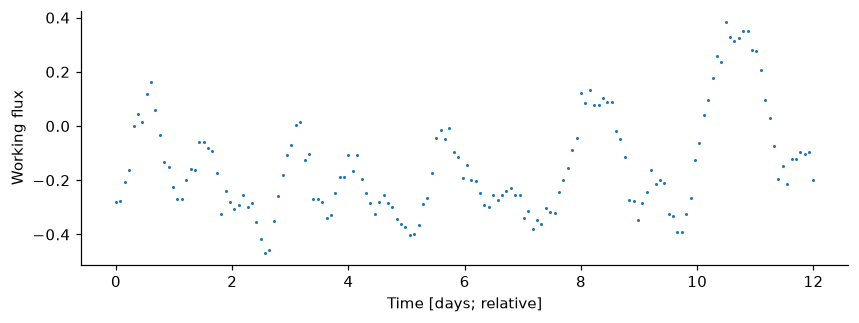

In [2]:
# Draw 160 observations over 12 days from a quasi-periodic Gaussian process.
# Set 2.5-day recurrence and a 5-day evolution timescale for the correlated signal.
# Use a GP standard deviation of 0.4 and independent measurement noise of 0.03.
lc = Nahiku.from_synthetic_gp(duration=12, n_points=160, period=2.5, amplitude=.4,
                              periodic_scale=1.2, length_scale=5, white_noise=.03, seed=4)

# Plot this seeded realization; successive cycles can differ in shape and amplitude.
lc.plot();

## Interpret the result

The 2.5-day period sets recurrence, while the RBF component's 5-day length scale allows the pattern to evolve. Unlike a fixed cosine, a quasi-periodic GP need not repeat exactly. `periodic_scale` is dimensionless and controls how rapidly correlation changes with phase separation within a cycle.

The amplitude specifies the GP's marginal standard deviation. The peak height and sample standard deviation vary between realizations. Independent white noise is added afterward; `flux_err` records only its standard deviation (or is `None` when `white_noise=0`). The seed makes the draw reproducible without resetting global random state. No anomalies are injected and the flux is not standardized automatically.

Dense synthetic sampling requires quadratic memory and cubic factorization time. This example draws from a specified covariance without fitting GP hyperparameters to observations.

Consult the API reference for parameter and return-value details.